In [173]:
import random
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from networkx.algorithms.approximation import steiner_tree

In [174]:
# ---------------------------------------------------------------------
# DISTRICT GENERATOR
# ---------------------------------------------------------------------
class DistrictGenerator:

    # ---------------------------------------------------------------------
    # Constructor
    # ---------------------------------------------------------------------
    def __init__(self,
                 width=1200,
                 height=800,
                 rows=5,
                 cols=7,
                 street_width=15,
                 n_substations=100,
                 block_variation=0.12,
                 perturbation=5,
                 seed=42):

        self.width = width
        self.height = height

        self.rows = rows
        self.cols = cols

        self.street_width = street_width
        self.block_variation = block_variation

        self.n_substations = n_substations

        self.perturbation = perturbation

        self.seed = seed

        random.seed(seed)

        self.blocks = []
        self.buildings = []

        self.street_nodes = {}
        self.street_edges = []

        self.street_graph = nx.Graph()

    # ---------------------------------------------------------------------
    # Utilities
    # ---------------------------------------------------------------------
    def random_partition(self, total, n):

        mean = total / n

        values = [
            mean * (1 + random.uniform(-self.block_variation,
                                       self.block_variation))
            for _ in range(n)
        ]

        scale = total / sum(values)
        values = [v * scale for v in values]
        values[-1] = total - sum(values[:-1])

        return values

    def nearest_node(self, x, y):

        return min(
            self.street_nodes,
            key=lambda k:
            abs(self.street_nodes[k][0] - x)
            + abs(self.street_nodes[k][1] - y)
        )

    # ---------------------------------------------------------------------
    # Street grid
    # ---------------------------------------------------------------------
    def build_street_grid(self):
            usable_width = self.width - (self.cols + 1) * self.street_width
            usable_height = self.height - (self.rows + 1) * self.street_width

            self.block_widths = self.random_partition(usable_width, self.cols)
            self.block_heights = self.random_partition(usable_height, self.rows)

            self.x = [0]
            for bw in self.block_widths:
                self.x.append(self.x[-1] + self.street_width)
                self.x.append(self.x[-1] + bw)

            self.y = [0]
            for bh in self.block_heights:
                self.y.append(self.y[-1] + self.street_width)
                self.y.append(self.y[-1] + bh)

            center_x = []
            for i in range(0, len(self.x), 2):
                cx = (self.x[i] + self.x[i+1]) / 2 if i+1 < len(self.x) else self.x[i]
                center_x.append(cx)

            center_y = []
            for j in range(0, len(self.y), 2):
                cy = (self.y[j] + self.y[j+1]) / 2 if j+1 < len(self.y) else self.y[j]
                center_y.append(cy)

            self.street_nodes = {}
            for i, cx in enumerate(center_x):
                for j, cy in enumerate(center_y):
                    self.street_nodes[(i, j)] = (cx, cy)

            self.street_edges = []
            for i in range(len(center_x) - 1):
                for j in range(len(center_y)):
                    self.street_edges.append(((i, j), (i+1, j)))

            for i in range(len(center_x)):
                for j in range(len(center_y) - 1):
                    self.street_edges.append(((i, j), (i, j+1)))

            self.street_graph = nx.Graph()
            for node, pos in self.street_nodes.items():
                self.street_graph.add_node(node, pos=pos)

            for n1, n2 in self.street_edges:
                x1, y1 = self.street_nodes[n1]
                x2, y2 = self.street_nodes[n2]
                L = abs(x2 - x1) + abs(y2 - y1)
                self.street_graph.add_edge(n1, n2, length=L)

    # ---------------------------------------------------------------------
    # Blocks
    # ---------------------------------------------------------------------
    def build_blocks(self):

        block_id = 0

        for c in range(self.cols):

            for r in range(self.rows):

                x0 = self.x[2*c+1]
                y0 = self.y[2*r+1]

                self.blocks.append({

                    "id": block_id,

                    "x": x0,
                    "y": y0,

                    "width": self.block_widths[c],
                    "height": self.block_heights[r],

                    "area":
                    self.block_widths[c] *
                    self.block_heights[r]

                })

                block_id += 1

    # ---------------------------------------------------------------------
    # Buildings
    # ---------------------------------------------------------------------
    def build_buildings(self):

        building_id = 0

        block_index = 0
        for c in range(self.cols):
            for r in range(self.rows):

                block  = self.blocks[block_index]
                x0     = block["x"]
                y0     = block["y"]
                bw     = block["width"]
                bh     = block["height"]

                available_sides = []
                if r < self.rows - 1: available_sides.append("N")  # non top
                if r > 0:             available_sides.append("S")  # non bottom
                if c < self.cols - 1: available_sides.append("E")  # non right
                if c > 0:             available_sides.append("W")  # non left

                if not available_sides:
                    block_index += 1
                    continue

                n = self._allocation[block_index]

                front_lengths = {
                    "N": bw, "S": bw,
                    "E": bh, "W": bh
                }
                avail_lengths = {s: front_lengths[s]
                                 for s in available_sides}
                total_len     = sum(avail_lengths.values())

                front_counts = {}
                assigned     = 0
                sides_sorted = sorted(avail_lengths,
                                      key=avail_lengths.get,
                                      reverse=True)

                for i, side in enumerate(sides_sorted):
                    if i == len(sides_sorted) - 1:
                        front_counts[side] = n - assigned
                    else:
                        cnt = round(n * avail_lengths[side] / total_len)
                        cnt = max(0, cnt)
                        front_counts[side] = cnt
                        assigned += cnt

                MARGIN  = self.street_width * 0.5
                MIN_GAP = 15.0

                for side, cnt in front_counts.items():
                    if cnt <= 0:
                        continue

                    if side in ("N", "S"):
                        axis_len  = bw
                        axis_start = x0
                        fixed_coord = y0 + bh - MARGIN if side == "N" \
                                      else y0 + MARGIN
                    else:
                        axis_len  = bh
                        axis_start = y0
                        fixed_coord = x0 + bw - MARGIN if side == "E" \
                                      else x0 + MARGIN

                    spacing = axis_len / (cnt + 1)
                    spacing = max(spacing, MIN_GAP)

                    for k in range(cnt):
                        pos = axis_start + spacing * (k + 1)
                        jitter = random.uniform(
                            -self.perturbation, self.perturbation)
                        pos = max(axis_start + MIN_GAP,
                                  min(axis_start + axis_len - MIN_GAP,
                                      pos + jitter))

                        if side in ("N", "S"):
                            bx, by = pos, fixed_coord
                        else:
                            bx, by = fixed_coord, pos

                        node = self.nearest_node(bx, by)

                        self.buildings.append({
                            "id"          : building_id,
                            "x"           : bx,
                            "y"           : by,
                            "block"       : block["id"],
                            "street_node" : node
                        })
                        building_id += 1

                block_index += 1

    # ---------------------------------------------------------------------
    # Generate
    # ---------------------------------------------------------------------
    def generate(self):

            self.build_street_grid()
            self.build_blocks()

            n_blocks = len(self.blocks)

            avail_counts = []
            for idx in range(n_blocks):
                c = idx // self.rows
                r = idx  % self.rows
                cnt = 0
                if r < self.rows - 1: cnt += 1
                if r > 0:             cnt += 1
                if c < self.cols - 1: cnt += 1
                if c > 0:             cnt += 1
                avail_counts.append(max(cnt, 1))

            total_avail = sum(avail_counts)
            raw = [self.n_substations * a / total_avail
                   for a in avail_counts]
            allocation = [max(1, round(v)) for v in raw]

            diff = self.n_substations - sum(allocation)
            for i in range(abs(diff)):
                idx = i % n_blocks
                allocation[idx] += 1 if diff > 0 else -1
                allocation[idx]  = max(0, allocation[idx])

            self._allocation = allocation

            self.build_buildings()

            return self

    # ---------------------------------------------------------------------
    # Plot
    # ---------------------------------------------------------------------
    def plot(self, show_labels=False):

        fig, ax = plt.subplots(figsize=(14, 9))

        ax.set_facecolor('#AAAAAA')

        # Blocks
        colors = ['#F0EEE8', '#EDEAE0', '#F2F0EA', '#EDE8E0']
        for idx, block in enumerate(self.blocks):
            ax.add_patch(
                patches.Rectangle(
                    (block["x"], block["y"]),
                    block["width"],
                    block["height"],
                    facecolor=colors[idx % len(colors)],
                    edgecolor='none',
                    linewidth=0,
                    zorder=1
                )
            )

        # Streets
        for n1, n2 in self.street_edges:
            x1, y1 = self.street_nodes[n1]
            x2, y2 = self.street_nodes[n2]
            ax.plot(
                [x1, x2], [y1, y2],
                color='white',
                lw=1.5,
                zorder=2
            )

        # Buildings
        xs = [b["x"] for b in self.buildings]
        ys = [b["y"] for b in self.buildings]
        ax.scatter(
            xs, ys,
            color='#CC2200',
            s=50,
            zorder=5,
            marker='s',
            edgecolors='white',
            linewidths=0.4
        )

        if show_labels:
            for b in self.buildings:
                ax.annotate(
                    str(b["id"]),
                    (b["x"], b["y"]),
                    fontsize=5,
                    color='white',
                    ha='center',
                    va='center',
                    zorder=6
                )

        ax.set_xlim(-20, self.width + 20)
        ax.set_ylim(-20, self.height + 20)
        ax.set_aspect('equal')
        ax.axis('off')

        ax.set_title(
            f'Synthetic Urban District\n'
            f'{self.cols}×{self.rows} blocks  |  '
            f'{self.width}×{self.height} m  |  '
            f'{len(self.buildings)} substations',
            fontsize=12,
            pad=12
        )

        plt.tight_layout()
        plt.show()

In [175]:
class NetworkBuilder:
    def __init__(self, district):
        self.district = district

        self.network_graph = district.street_graph.copy()

        self.terminals = []
        self.plant_node = None
        self.projection_to_building = {}

        self.main_network = None  # Steiner Tree
        self.branch_pipes = []    # Building branches

    def _project_point_on_segment(self, px, py, x1, y1, x2, y2):
        dx, dy = x2 - x1, y2 - y1
        if dx == 0 and dy == 0:
            return x1, y1, 0.0

        t = ((px - x1) * dx + (py - y1) * dy) / (dx * dx + dy * dy)
        t = max(0.0, min(1.0, t))

        proj_x = x1 + t * dx
        proj_y = y1 + t * dy
        dist = ((px - proj_x)**2 + (py - proj_y)**2)**0.5
        return proj_x, proj_y, dist

    def build_network(self, plant_position=(0, 0)):

        self.plant_node = plant_position
        self.terminals.append(self.plant_node)

        for building in self.district.buildings:
            bx, by = building["x"], building["y"]

            best_edge = None
            min_dist = float("inf")
            best_proj = (0, 0)

            for u, v in self.network_graph.edges():
                pos_u = self.network_graph.nodes[u]["pos"]
                pos_v = self.network_graph.nodes[v]["pos"]

                px, py, d = self._project_point_on_segment(bx, by, pos_u[0], pos_u[1], pos_v[0], pos_v[1])
                if d < min_dist:
                    min_dist = d
                    best_proj = (px, py)
                    best_edge = (u, v)

            proj_node_id = f"proj_b_{building['id']}"
            u, v = best_edge

            pos_u = self.network_graph.nodes[u]["pos"]
            pos_v = self.network_graph.nodes[v]["pos"]

            len_u = abs(best_proj[0] - pos_u[0]) + abs(best_proj[1] - pos_u[1])
            len_v = abs(pos_v[0] - best_proj[0]) + abs(pos_v[1] - best_proj[1])

            if self.network_graph.has_edge(u, v):
                self.network_graph.remove_edge(u, v)

            self.network_graph.add_node(proj_node_id, pos=best_proj)
            self.network_graph.add_edge(u, proj_node_id, length=len_u)
            self.network_graph.add_edge(proj_node_id, v, length=len_v)

            self.terminals.append(proj_node_id)
            self.projection_to_building[proj_node_id] = building

        self.main_network = steiner_tree(self.network_graph, self.terminals, weight='length')

        self.branch_pipes = []
        for node in self.main_network.nodes():
            if node in self.projection_to_building:
                b = self.projection_to_building[node]
                self.branch_pipes.append({
                    "from_pos": self.network_graph.nodes[node]["pos"],
                    "to_pos": (b["x"], b["y"])
                })

    def plot_network(self):
        fig, ax = plt.subplots(figsize=(14, 9))
        ax.set_facecolor('#AAAAAA')

        colors = ['#F0EEE8', '#EDEAE0', '#F2F0EA', '#EDE8E0']
        for idx, block in enumerate(self.district.blocks):
            ax.add_patch(patches.Rectangle(
                (block["x"], block["y"]), block["width"], block["height"],
                facecolor=colors[idx % len(colors)], edgecolor='none', zorder=1
            ))

        for n1, n2 in self.district.street_edges:
            pass

        # 1. Distribution line
        edges_list = list(self.main_network.edges())
        for u, v in edges_list:
            pos_u = self.network_graph.nodes[u]["pos"]
            pos_v = self.network_graph.nodes[v]["pos"]
            is_first = (u == edges_list[0][0] and v == edges_list[0][1])
            ax.plot([pos_u[0], pos_v[0]], [pos_u[1], pos_v[1]],
                    color='#FF8C00', lw=3, label='Distribution Network' if is_first else "", zorder=3)

        # 2. Building branches
        for i, pipe in enumerate(self.branch_pipes):
            p1, p2 = pipe["from_pos"], pipe["to_pos"]
            ax.plot([p1[0], p2[0]], [p1[1], p2[1]],
                    color='#FF8C00', lw=1.5, linestyle=':', label='Buildings Branch' if i == 0 else "", zorder=4)

        # Buildings
        xs = [b["x"] for b in self.district.buildings]
        ys = [b["y"] for b in self.district.buildings]
        ax.scatter(xs, ys, color='#CC2200', s=50, zorder=5, marker='s', edgecolors='white', linewidths=0.4, label='Buildings')

        # Source
        plant_pos = self.network_graph.nodes[self.plant_node]["pos"]
        ax.scatter(plant_pos[0], plant_pos[1], color='#660000', s=250, marker='o', edgecolors='white', linewidths=1, label='Source', zorder=6)

        ax.set_xlim(-20, self.district.width + 20)
        ax.set_ylim(-20, self.district.height + 20)
        ax.set_aspect('equal')
        ax.axis('off')
        ax.legend(loc='lower center', frameon=True, facecolor='white', edgecolor='none')

        plt.tight_layout()
        plt.show()

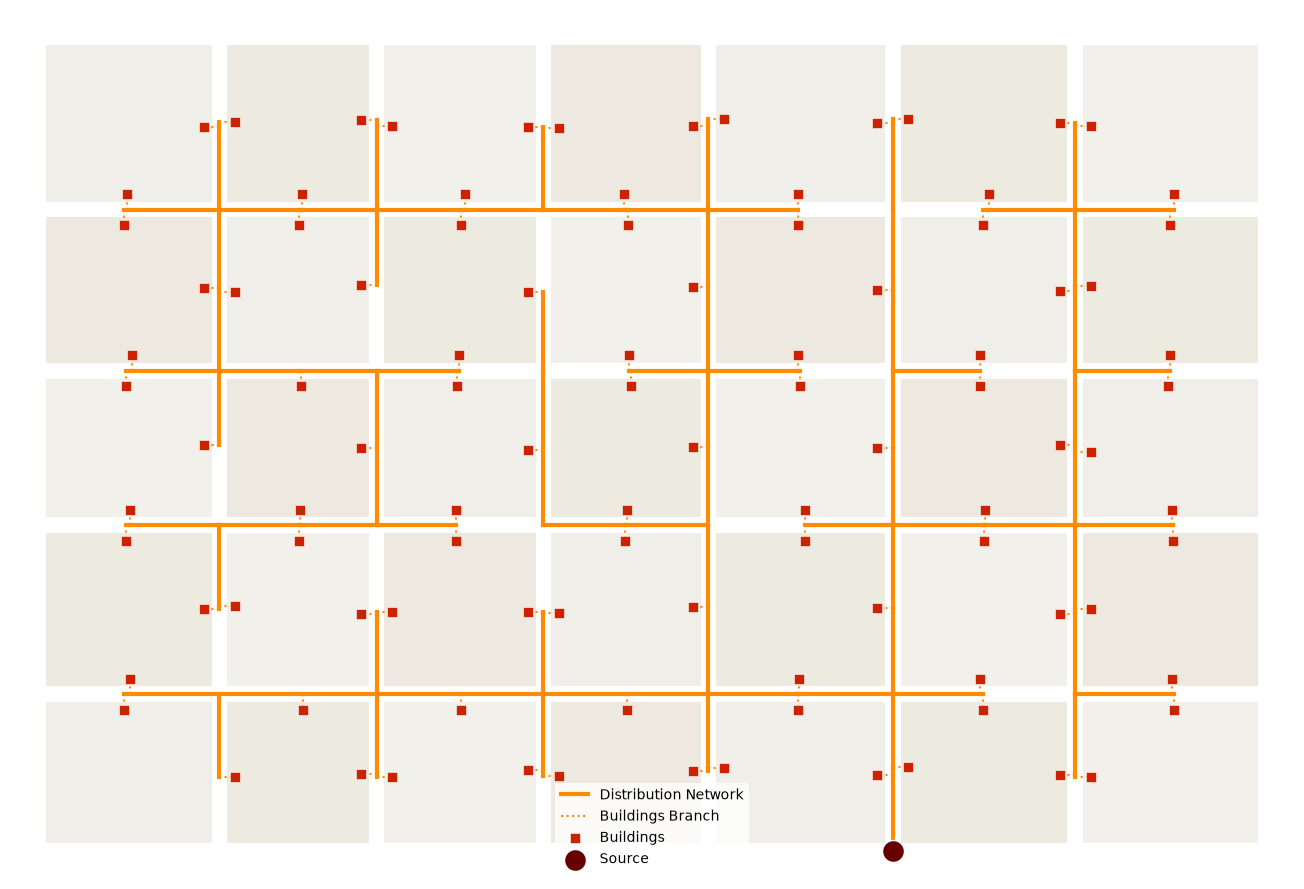

In [176]:
district = DistrictGenerator(
    width=1200,
    height=800,
    rows=5,
    cols=7,
    n_substations=100,
    seed=42
)

district.generate()

network_builder = NetworkBuilder(district)
network_builder.build_network(plant_position=(5,0))

network_builder.plot_network()